# Integrated Group Pipeline
This notebook combines preprocessing steps from all members.

## 1. Import Libraries

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.ensemble import RandomForestClassifier

## 2. Load Raw Dataset

In [2]:
# Load dataset from data/raw/

from google.colab import drive
drive.mount('/content/drive')

!ls /content/drive/

df = pd.read_csv('/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/data/raw/Student Depression Dataset.csv')

Mounted at /content/drive
MyDrive


## 3. Member Contributions

### IT24102082 Preprocessing - Cleaning the data

In [3]:
#display first 5 rows
df.head()


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33,Visakhapatnam,Student,5,0,8.97,2,0,5-6 hours,Healthy,B.Pharm,Yes,3,1.0,No,1
1,8,Female,24,Bangalore,Student,2,0,5.90,5,0,5-6 hours,Moderate,BSc,No,3,2.0,Yes,0
2,26,Male,31,Srinagar,Student,3,0,7.03,5,0,Less than 5 hours,Healthy,BA,No,9,1.0,Yes,0
3,30,Female,28,Varanasi,Student,3,0,5.59,2,0,7-8 hours,Moderate,BCA,Yes,4,5.0,Yes,1
4,32,Female,25,Jaipur,Student,4,0,8.13,3,0,5-6 hours,Moderate,M.Tech,Yes,1,1.0,No,0


In [4]:
#dropping unwanted columns
columns_to_drop = [
'id', 'City','Profession', 'Work Pressure', 'Job Satisfaction','Degree', 'Financial Stress', 'Study Satisfaction','Academic Pressure','Sleep Duration'
]
existing_columns_to_drop = [col for col in columns_to_drop if col in df.columns]
if existing_columns_to_drop:
    df.drop(columns=existing_columns_to_drop, inplace=True)
    print(f"Successfully removed columns: {existing_columns_to_drop}")
else:
    print("No specified columns found to drop.")

Successfully removed columns: ['id', 'City', 'Profession', 'Work Pressure', 'Job Satisfaction', 'Degree', 'Financial Stress', 'Study Satisfaction', 'Academic Pressure', 'Sleep Duration']


In [17]:
#renaming columns
df = df.rename(columns={"Have you ever had suicidal thoughts ?":"Suicidal_Thoughts", "Family History of Mental Illness":"Family_History"})

In [5]:
#print first 5 rows of the dataset after removing unwanted columns
df.head()

,Gender,Age,CGPA,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Family History of Mental Illness,Depression
0,Male,33,8.97,Healthy,Yes,3,No,1
1,Female,24,5.90,Moderate,No,3,Yes,0
2,Male,31,7.03,Healthy,No,9,Yes,0
3,Female,28,5.59,Moderate,Yes,4,Yes,1
4,Female,25,8.13,Moderate,Yes,1,No,0


In [6]:
#print last 5 rows of the dataset
df.tail()

,Gender,Age,CGPA,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Family History of Mental Illness,Depression
27896,Female,27,5.75,Unhealthy,Yes,7,Yes,0
27897,Male,27,9.40,Healthy,No,0,Yes,0
27898,Male,31,6.61,Unhealthy,No,12,No,0
27899,Female,18,6.88,Healthy,Yes,10,No,1
27900,Male,27,9.24,Healthy,Yes,2,Yes,1


In [7]:
#removing duplicates
duplicates_before = df.duplicated().sum()
print(f"Found {duplicates_before} duplicate rows before cleaning.")

df.drop_duplicates(inplace=True)

duplicates_after = df.duplicated().sum()
print(f"Removed duplicates. There are now {duplicates_after} duplicate rows.")
print(f"The dataset now has {len(df)} unique rows.")

Found 616 duplicate rows before cleaning.
Removed duplicates. There are now 0 duplicate rows.
The dataset now has 27285 unique rows.


In [8]:
# Check the data types of each column in the dataframe
df.dtypes

,0
Gender,object
Age,int64
CGPA,float64
Dietary Habits,object
Have you ever had suicidal thoughts ?,object
Work/Study Hours,int64
Family History of Mental Illness,object
Depression,int64


In [9]:
#identifying missing values
print(df.isnull().sum())

Gender                                   0
Age                                      0
CGPA                                     0
Dietary Habits                           0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Family History of Mental Illness         0
Depression                               0
dtype: int64


### IT24102168 Preprocessing - One-Hot encoding

In [10]:
# Manual one-hot encoding for Gender
df['Gender_Male'] = (df['Gender'] == 'Male').astype(int)
df['Gender_Female'] = (df['Gender'] == 'Female').astype(int)

print("DataFrame with manual one-hot encoding for Gender:")
df.head(5)

DataFrame with manual one-hot encoding for Gender:


,Gender,Age,CGPA,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Family History of Mental Illness,Depression,Gender_Male,Gender_Female
0,Male,33,8.97,Healthy,Yes,3,No,1,1,0
1,Female,24,5.90,Moderate,No,3,Yes,0,0,1
2,Male,31,7.03,Healthy,No,9,Yes,0,1,0
3,Female,28,5.59,Moderate,Yes,4,Yes,1,0,1
4,Female,25,8.13,Moderate,Yes,1,No,0,0,1


In [11]:
# Drop the original gender column
df = df.drop('Gender', axis=1)
df.head()

,Age,CGPA,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Family History of Mental Illness,Depression,Gender_Male,Gender_Female
0,33,8.97,Healthy,Yes,3,No,1,1,0
1,24,5.90,Moderate,No,3,Yes,0,0,1
2,31,7.03,Healthy,No,9,Yes,0,1,0
3,28,5.59,Moderate,Yes,4,Yes,1,0,1
4,25,8.13,Moderate,Yes,1,No,0,0,1


In [13]:
#one-hot encoding for Dietary Habits
df['Diet_Healthy'] = (df['Dietary Habits'] == 'Healthy').astype(int)
df['Diet_Moderate'] = (df['Dietary Habits'] == 'Moderate').astype(int)
df['Diet_Unhealthy'] = (df['Dietary Habits'] == 'Unhealthy').astype(int)

print("DataFrame with manual one-hot encoding:")
df.head(5)

DataFrame with manual one-hot encoding:


,Age,CGPA,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Family History of Mental Illness,Depression,Gender_Male,Gender_Female,Diet_Healthy,Diet_Moderate,Diet_Unhealthy
0,33,8.97,Healthy,Yes,3,No,1,1,0,1,0,0
1,24,5.90,Moderate,No,3,Yes,0,0,1,0,1,0
2,31,7.03,Healthy,No,9,Yes,0,1,0,1,0,0
3,28,5.59,Moderate,Yes,4,Yes,1,0,1,0,1,0
4,25,8.13,Moderate,Yes,1,No,0,0,1,0,1,0


In [14]:
#Drop the original Dietary Habits column
df = df.drop('Dietary Habits', axis=1)
df.head()

,Age,CGPA,Have you ever had suicidal thoughts ?,Work/Study Hours,Family History of Mental Illness,Depression,Gender_Male,Gender_Female,Diet_Healthy,Diet_Moderate,Diet_Unhealthy
0,33,8.97,Yes,3,No,1,1,0,1,0,0
1,24,5.90,No,3,Yes,0,0,1,0,1,0
2,31,7.03,No,9,Yes,0,1,0,1,0,0
3,28,5.59,Yes,4,Yes,1,0,1,0,1,0
4,25,8.13,Yes,1,No,0,0,1,0,1,0


### IT24102091 Preprocessing - Label Encoding

In [18]:
#Label encoding for Family History of Mental Illness and Suicidal Thoughts

# Family History of Mental Illness
# The column name in the dataframe is now 'Family_History'
df['Family_History'] = df['Family_History'].map({'No': 0, 'Yes': 1})

# Suicidal Thoughts
# The column name in the dataframe is now 'Suicidal_Thoughts'
df['Suicidal_Thoughts'] = df['Suicidal_Thoughts'].map({'No': 0, 'Yes': 1})

df.head()

,Age,CGPA,Suicidal_Thoughts,Work/Study Hours,Family_History,Depression,Gender_Male,Gender_Female,Diet_Healthy,Diet_Moderate,Diet_Unhealthy
0,33,8.97,1,3,0,1,1,0,1,0,0
1,24,5.90,0,3,1,0,0,1,0,1,0
2,31,7.03,0,9,1,0,1,0,1,0,0
3,28,5.59,1,4,1,1,0,1,0,1,0
4,25,8.13,1,1,0,0,0,1,0,1,0


### IT24102079 Preprocessing - Outliers Removing

In [19]:
# Function to detect outliers using IQR
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"\n{column} Outlier Detection:")
    print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
    print(f"Lower Bound = {lower_bound}, Upper Bound = {upper_bound}")

    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    print(f"Number of outliers in {column}: {outliers.shape[0]}")
    return outliers

In [20]:
# Detect outliers in Age
outliers_age = detect_outliers_iqr(df, "Age")


Age Outlier Detection:
Q1 = 21.0, Q3 = 30.0, IQR = 9.0
Lower Bound = 7.5, Upper Bound = 43.5
Number of outliers in Age: 12


In [21]:
# Detect outliers in CGPA
outliers_Cgpa = detect_outliers_iqr(df, "CGPA")


CGPA Outlier Detection:
Q1 = 6.28, Q3 = 8.92, IQR = 2.6399999999999997
Lower Bound = 2.3200000000000007, Upper Bound = 12.879999999999999
Number of outliers in CGPA: 8


In [23]:
# Detect outliers in Study_Hours
outliers_study_hours = detect_outliers_iqr(df, "Work/Study Hours")


Work/Study Hours Outlier Detection:
Q1 = 4.0, Q3 = 10.0, IQR = 6.0
Lower Bound = -5.0, Upper Bound = 19.0
Number of outliers in Work/Study Hours: 0


In [24]:
# Function to remove outliers
def remove_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

# Remove outliers from Age and CGPA
df_clean = df.copy()
df_clean = remove_outliers_iqr(df_clean, "Age")
df_clean = remove_outliers_iqr(df_clean, "CGPA")

In [25]:
df.shape

(27285, 11)

### IT24102172 Preprocessing - Normalization

In [26]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
# Define numerical columns
numerical_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

# Initialize MinMaxScaler
scaler = MinMaxScaler()
# Apply Min-Max Scaling
# Apply normalization directly to df_clean
df_clean[numerical_cols] = scaler.fit_transform(df_clean[numerical_cols])
#print after normalization
print("\nDataset after Min-Max Normalization:")
df_clean.head()


Dataset after Min-Max Normalization:


,Age,CGPA,Suicidal_Thoughts,Work/Study Hours,Family_History,Depression,Gender_Male,Gender_Female,Diet_Healthy,Diet_Moderate,Diet_Unhealthy
0,0.60,0.792757,1.0,0.250000,0.0,1.0,1.0,0.0,1.0,0.0,0.0
1,0.24,0.175050,0.0,0.250000,1.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.52,0.402414,0.0,0.750000,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0.40,0.112676,1.0,0.333333,1.0,1.0,0.0,1.0,0.0,1.0,0.0
4,0.28,0.623742,1.0,0.083333,0.0,0.0,0.0,1.0,0.0,1.0,0.0


### IT24102042 Preprocessing - Feature Engineering

In [27]:
# Separate features and target
X = df.drop("Depression", axis=1)   # Features
y = df["Depression"]                # Target

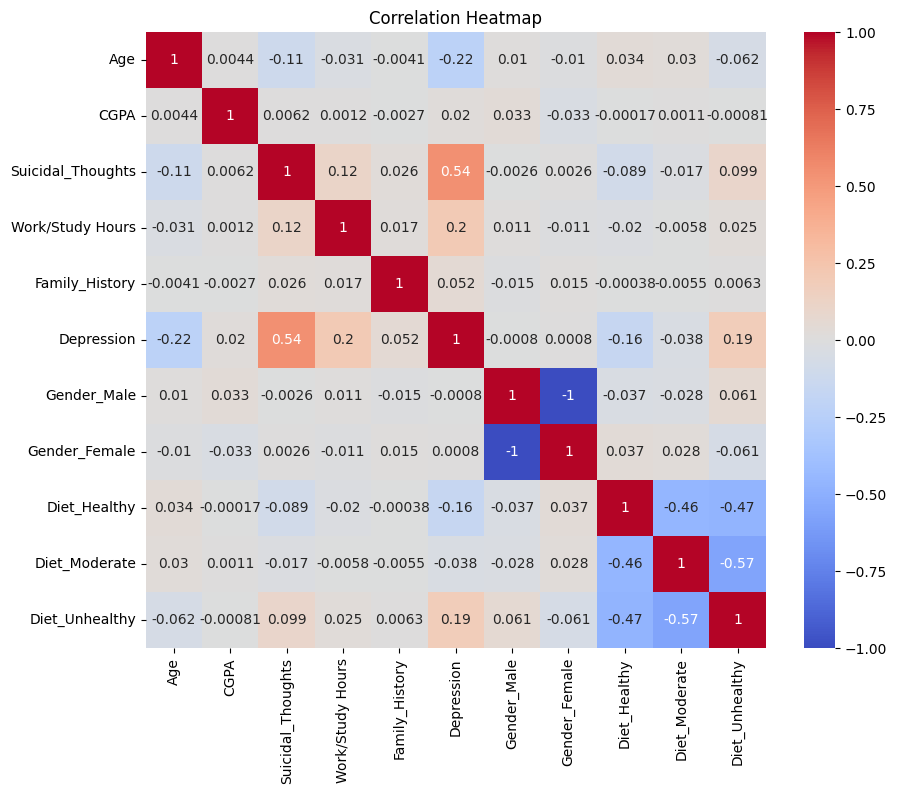

In [28]:
#Correlation Heatmap
plt.figure(figsize=(10,8))
# Drop non-numeric columns before calculating correlation
df_numeric = df
sns.heatmap(df_numeric.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [29]:
# Apply Chi-Square test
selector = SelectKBest(score_func=chi2, k=5)  # Keep top 5 features

X_new = selector.fit_transform(abs(X), y)  # abs() to avoid negatives

# Show selected feature names
selected_features = X.columns[selector.get_support()]
print("Selected Features:", selected_features)

Selected Features: Index(['Age', 'Suicidal_Thoughts', 'Work/Study Hours', 'Diet_Healthy',
       'Diet_Unhealthy'],
      dtype='object')


In [30]:
from sklearn.ensemble import RandomForestClassifier

X = df_clean.drop("Depression", axis=1)
y = df_clean["Depression"]

model = RandomForestClassifier(random_state=42)
model.fit(X, y)

importances = model.feature_importances_
features = X.columns

# Show ranked features
feature_importance = pd.DataFrame({"Feature": features, "Importance": importances})
feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print("Feature Importance Ranking:")
print(feature_importance.head(5))

Feature Importance Ranking:
             Feature  Importance
1               CGPA    0.376645
2  Suicidal_Thoughts    0.270625
0                Age    0.161775
3   Work/Study Hours    0.129241
9     Diet_Unhealthy    0.018923


/tmp/ipython-input-3830454810.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importance["Importance"], y=feature_importance["Feature"], palette="viridis")


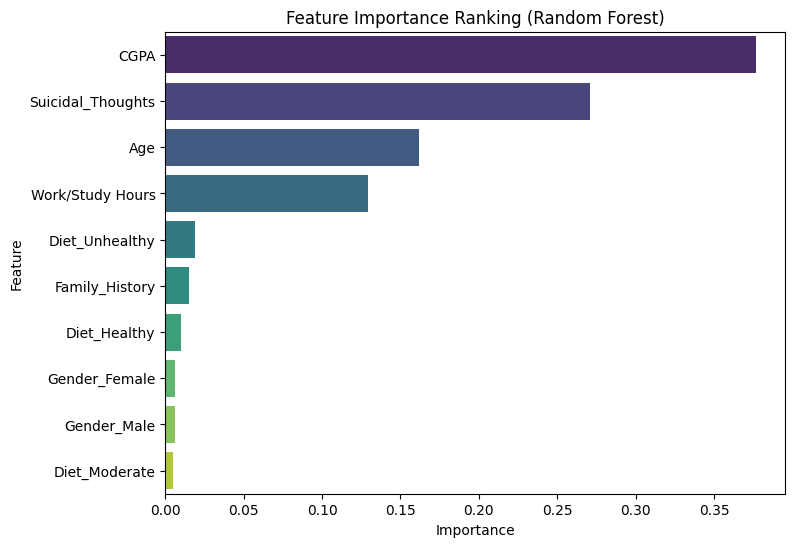

In [31]:
plt.figure(figsize=(8,6))
sns.barplot(x=feature_importance["Importance"], y=feature_importance["Feature"], palette="viridis")
plt.title("Feature Importance Ranking (Random Forest)")
plt.show()

## 4. Combine & Save Final Processed Dataset

In [32]:
# Save final dataset to results/outputs/
# Keep only selected features and target column
top5_features = feature_importance["Feature"].head(5).tolist()

final_df = df_clean[top5_features + ["Depression"]]
print("\nFinal Dataset with Top 5 Features:")
print(final_df.head())

# Save for next step
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/student_depression_Final.csv"
final_df.to_csv(save_path, index=False)

print(f"Final dataset saved at: {save_path}")
print("Final Shape:", final_df.shape)


Final Dataset with Top 5 Features:
       CGPA  Suicidal_Thoughts   Age  Work/Study Hours  Diet_Unhealthy  \
0  0.792757                1.0  0.60          0.250000             0.0   
1  0.175050                0.0  0.24          0.250000             0.0   
2  0.402414                0.0  0.52          0.750000             0.0   
3  0.112676                1.0  0.40          0.333333             0.0   
4  0.623742                1.0  0.28          0.083333             0.0   

   Depression  
0         1.0  
1         0.0  
2         0.0  
3         1.0  
4         0.0  
Final dataset saved at: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/student_depression_Final.csv
Final Shape: (27265, 6)
